**Human Movement Intelligence | Presented by: Reza Saadatyar (2026)**

**05 | Class-Weighted Temporal CNN and Matched Grouped Comparison**

![HARTH weighted-loss and grouped comparison schematic](../../images/05_consolidated_workflow.svg)

**Objective:** Compare standard and Train-derived class-weighted temporal CNNs, then benchmark the two CNN variants against Random Forest using matched participant-disjoint Development folds.

**Dataset:** Official NTNU AI Lab HARTH v2.0, with lower-back and thigh tri-axial acceleration at nominal 50 Hz. The classification task retains eight documented source activity classes (1–8).

**Protocol:** Reconstruct one shared cohort of 100-sample, label-pure windows with a 50-sample stride and a maximum of 500 windows per person. Experiment A uses one whole-participant Train/Validation/unused Development split; Experiment B uses three-fold GroupKFold over the same Development cohort. S023 and S032 are excluded throughout.

**Scope:** This is Development-only evidence. The fixed Validation and grouped cross-validation estimates are not interchangeable, and neither constitutes independent external validation.


**00. Colab Repository Setup**

Obtain the public repository checkout for the study's original source adapter, shared models and output utilities.


In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
import subprocess

repo_url = "https://github.com/RezaSaadatyar/human-movement-intelligence.git"
repo_path = Path("/content") / repo_url.rsplit("/", 1)[-1].removesuffix(".git")

if not repo_path.exists():
    subprocess.run(["git", "clone", "-q", repo_url, str(repo_path)], check=True)

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}


/content/human-movement-intelligence


**01. Imports and Research Environment**

Prepare dataset, splitting, modelling, evaluation and visualisation tools. Both experiments write current stage-specific outputs into the study output directory.


In [2]:
# =================== 01. Imports and Research Environment ====================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("wearable_activity_recognition")

# ----------------- 2. Scientific Computing and Data Analysis -----------------
import numpy as np
import pandas as pd

# --------------- 3. Machine Learning and Deep Learning Metrics ---------------
from sklearn.metrics import (
    f1_score, balanced_accuracy_score, confusion_matrix,
    ConfusionMatrixDisplay,
)
import torch

# ------------------- 4. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style, save_figure

plot_style(
    font_family="DejaVu Sans", title_size=12.5, title_weight="normal",
    label_size=11.5, label_weight="normal", tick_size=11, legend_size=10,
    figure_dpi=100, figure_size=(9, 4),
)

# ------------------ 5. HARTH and Shared Research Utilities -------------------
from harth_data import (
    HARTH_SUBJECTS, ACTIVITY_NAMES, SENSOR_COLUMNS,
    prepare_harth_window_cohort,
)
from core.data_splitting import split_group_indices
from core.temporal_cnn import train_temporal_cnn, compute_training_class_weights
from core.temporal_comparison import compare_models_group_cv
from core.ml_baselines import (
    classification_class_report, evaluate_predictions_by_subject,
)
from core.group_cross_validation import compare_models_by_subject
from core.output_download import download_outputs_from_colab

# ------------------ 6. Training Device and Output Directory ------------------
from core.computer_device import computer_device
device = computer_device()
DEVICE = device.type
output_dir = root / "wearable_activity_recognition" / "output"
output_dir.mkdir(parents=True, exist_ok=True)
print("Research output directory:", output_dir)


Repository up to date.
Compute device and system information
OS: Linux 6.6.159+
CPU: x86_64
Installed RAM: 12.7 GiB
NVIDIA GPU: Tesla T4
Total VRAM: 15.00 GiB
PyTorch version: 2.14.1+cu130
CUDA device: Tesla T4
CUDA runtime: 13.0
cuDNN version: 92800
PyTorch total VRAM: 14.56 GiB
Selected compute device: cuda
Research output directory: /content/human-movement-intelligence/wearable_activity_recognition/output


**02. Build the Shared Development Window Cohort**

Create one bounded, temporally continuous and label-pure source-window cohort; preserve row metadata and group IDs. Raw sequences are reconstructed from the official source rather than substituted with 30-feature statistical summaries.


In [3]:
# ============== 02. Build the Shared Development Window Cohort ===============

# ------------------- 1. Prepare Matched Development Cohort -------------------
RESERVED_TEST = {"S023", "S032"}
DEVELOPMENT_SUBJECTS = sorted(set(HARTH_SUBJECTS) - RESERVED_TEST)
TASK_CLASSES = tuple(range(1, 9))

X, y, metadata, overview = prepare_harth_window_cohort(
    subjects=DEVELOPMENT_SUBJECTS,
    data_dir=root / "data/raw/harth_v2",
    task_classes=TASK_CLASSES, max_windows_per_subject=500,
    window_size=100, step_size=50, sampling_rate=50,
)

if set(metadata["subject_id"]) & RESERVED_TEST:
    raise ValueError("Reserved participants must not be loaded.")

# ------------------------ 2. Summarise Source Windows ------------------------
if not (len(X) == len(y) == len(metadata)):
    raise ValueError("Window, label and metadata rows must align.")
if X.shape[1:] != (len(SENSOR_COLUMNS), 100):
    raise ValueError("Expected six-channel, 100-sample temporal windows.")
if not np.array_equal(metadata["label"].to_numpy(), y):
    raise ValueError("Window metadata and labels are misaligned.")
print("Shared signal cohort:", X.shape)

display(overview[["subject_id", "eligible_windows", "sampled_windows"]])


Downloaded 59,108,125 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S006.csv
HARTH subject S006: 408,709 rows, 6 sensors
Input signal: 408,709 samples, 6 channels
Candidate windows: 8,173
Retained windows: 7,441 | Shape: (7441, 6, 100)
Rejected candidates: 732
Downloaded 60,603,857 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S008.csv
HARTH subject S008: 418,989 rows, 6 sensors
Input signal: 418,989 samples, 6 channels
Candidate windows: 8,378
Retained windows: 7,564 | Shape: (7564, 6, 100)
Rejected candidates: 814
Downloaded 22,408,603 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S009.csv
HARTH subject S009: 154,464 rows, 6 sensors
Input signal: 154,464 samples, 6 channels
Candidate windows: 3,088
Retained windows: 2,885 | Shape: (2885, 6, 100)
Rejected candidates: 203
Downloaded 50,898,931 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S010.csv
HARTH subject S010: 351,649 rows, 6 sensors
Input signal: 351,649 sa

/content/human-movement-intelligence/wearable_activity_recognition/code/src/harth_data.py:327: UserWarning: Unexpected HARTH activity codes: [10, 11, 17] (4,512 rows in S030.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S030: 245,994 rows, 6 sensors
Input signal: 245,994 samples, 6 channels
Candidate windows: 4,918
Retained windows: 3,335 | Shape: (3335, 6, 100)
Rejected candidates: 1,583
Downloaded 22,728,229 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S031.csv


/content/human-movement-intelligence/wearable_activity_recognition/code/src/harth_data.py:327: UserWarning: Unexpected HARTH activity codes: [10, 11] (334 rows in S031.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S031: 269,560 rows, 6 sensors
Input signal: 269,560 samples, 6 channels
Candidate windows: 5,390
Retained windows: 4,411 | Shape: (4411, 6, 100)
Rejected candidates: 979
Downloaded 16,070,724 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S033.csv
HARTH subject S033: 201,688 rows, 6 sensors
Input signal: 201,688 samples, 6 channels
Candidate windows: 4,032
Retained windows: 3,687 | Shape: (3687, 6, 100)
Rejected candidates: 345
Downloaded 15,031,875 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S034.csv
HARTH subject S034: 188,202 rows, 6 sensors
Input signal: 188,202 samples, 6 channels
Candidate windows: 3,763
Retained windows: 3,351 | Shape: (3351, 6, 100)
Rejected candidates: 412
Downloaded 14,899,779 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S035.csv
HARTH subject S035: 181,251 rows, 6 sensors
Input signal: 181,251 samples, 6 channels
Candidate windows: 3,624
Retained windows: 3,337 | Shape: (3337, 6, 100)
Reje

/content/human-movement-intelligence/wearable_activity_recognition/code/src/harth_data.py:327: UserWarning: Unexpected HARTH activity codes: [10] (1,422 rows in S037.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S037: 206,379 rows, 6 sensors
Input signal: 206,379 samples, 6 channels
Candidate windows: 4,126
Retained windows: 3,468 | Shape: (3468, 6, 100)
Rejected candidates: 658
Downloaded 15,185,213 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S038.csv
HARTH subject S038: 184,992 rows, 6 sensors
Input signal: 184,992 samples, 6 channels
Candidate windows: 3,698
Retained windows: 3,355 | Shape: (3355, 6, 100)
Rejected candidates: 343
Temporal cohort: 29 subjects, X=(14201, 6, 100)
Shared signal cohort: (14201, 6, 100)


,subject_id,eligible_windows,sampled_windows
0,S006,6708,500
1,S008,7392,500
2,S009,201,201
3,S010,6077,500
4,S012,7309,500
5,S013,6402,500
6,S014,6299,500
7,S015,7453,500
8,S016,6272,500
9,S017,6678,500


**03. Inspect Class Support and Split Participants**

Summarise the eight-class support per person. For the loss-ablation experiment, create a participant-disjoint 70/20/10 Train/Validation/unused Development split with seed 42; the third partition is not the reserved Test.


In [4]:
# ============= 03. Inspect Class Support and Split Participants ==============

# ------------------ 1. Inspect Participant Activity Support ------------------
coverage = pd.crosstab(metadata["subject_id"], metadata["label"]).reindex(
    index=DEVELOPMENT_SUBJECTS, columns=TASK_CLASSES, fill_value=0
)
coverage.columns = [f"{code}: {ACTIVITY_NAMES[code]}" for code in TASK_CLASSES]
display(coverage)

print("Independent participants supporting each class:",
      (coverage > 0).sum(axis=0).to_dict())

# ------------------ 2. Recreate Participant-Disjoint Split -------------------
parts = split_group_indices(
    metadata["subject_id"].to_numpy(),
    train_fraction=0.70, validation_fraction=0.20,
    test_fraction=0.10, random_state=42,
)
train_idx, val_idx = parts["train"], parts["validation"]

X_train, X_val = X[train_idx], X[val_idx]
y_train, y_val = y[train_idx], y[val_idx]

# --------------------- 3. Verify Participant Separation ----------------------
val_subject_ids = metadata.iloc[val_idx]["subject_id"].to_numpy()

train_subject_ids = metadata.iloc[train_idx]["subject_id"].to_numpy()
unused_subject_ids = metadata.iloc[parts["test"]]["subject_id"].to_numpy()
if set(train_subject_ids) & set(val_subject_ids) or set(unused_subject_ids) & (
    set(train_subject_ids) | set(val_subject_ids)
):
    raise ValueError("Development participant partitions overlap.")
if set(np.unique(y_train)) != set(TASK_CLASSES):
    raise ValueError("One or more target classes are absent from Train.")
print("Train windows:", len(y_train), "Validation windows:", len(y_val))
print("Unused development windows:", len(parts["test"]))


,1: Walking,2: Running,3: Shuffling,4: Stairs ascending,5: Stairs descending,6: Standing,7: Sitting,8: Lying
subject_id,,,,,,,,
S006,17,0,4,2,3,80,375,19
S008,20,0,22,0,1,65,392,0
S009,91,0,0,7,9,94,0,0
S010,270,0,18,8,3,125,76,0
S012,13,2,3,5,2,24,426,25
S013,41,5,35,4,1,56,348,10
S014,20,4,10,7,3,68,373,15
S015,65,3,2,6,5,78,257,84
S016,57,3,10,0,2,66,301,61


Independent participants supporting each class: {'1: Walking': 29, '2: Running': 19, '3: Shuffling': 26, '4: Stairs ascending': 24, '5: Stairs descending': 25, '6: Standing': 29, '7: Sitting': 28, '8: Lying': 23}
Independent groups: 29
train: 20 groups | 10,000 rows
validation: 6 groups | 2,701 rows
test: 3 groups | 1,500 rows
Train windows: 10000 Validation windows: 2701
Unused development windows: 1500


**04. Calculate Train-Only Class Weights**

Calculate inverse-square-root class-frequency weights on Train labels only and normalise their arithmetic mean to one. The labels and Validation distribution are not modified.


In [5]:
# ================== 04. Calculate Train-Only Class Weights ===================

# --------------------- 1. Compute Training Class Weights ---------------------
training_counts = pd.Series(y_train).value_counts().reindex(TASK_CLASSES, fill_value=0)
weights = compute_training_class_weights(y_train, TASK_CLASSES, method="inverse_sqrt")  # Derive weighting solely from Train labels.

# ------------------------- 2. Inspect Class Support --------------------------
weight_table = pd.DataFrame({
    "activity": [ACTIVITY_NAMES[c] for c in TASK_CLASSES],
    "train_windows": training_counts.to_numpy(),
    "inverse_sqrt_weight": weights,
})
if not (training_counts > 0).all():
    raise ValueError("Every defined class must occur in Train.")

display(weight_table.round(4))


,activity,train_windows,inverse_sqrt_weight
0,Walking,2987,0.3973
1,Running,940,0.7083
2,Shuffling,169,1.6704
3,Stairs ascending,156,1.7386
4,Stairs descending,145,1.8034
5,Standing,1502,0.5603
6,Sitting,3240,0.3815
7,Lying,861,0.7401


**05. Train Matched Standard and Weighted CNNs**

Fit both CNN loss conditions with identical Train/Validation windows, architecture, five epochs, batch size 128, Adam learning rate 0.001 and seed 42. Only the loss weighting differs.


In [6]:
# =============== 05. Train Matched Standard and Weighted CNNs ================

# ------------------- 1. Configure Matched CNN Experiments --------------------
settings = dict(
    X_train=X_train, y_train=y_train,
    X_validation=X_val, y_validation=y_val,
    classes=TASK_CLASSES, epochs=5, batch_size=128,
    learning_rate=1e-3, seed=42,
    device=DEVICE,
)
runs = {}

# --------------------- 2. Fit Standard and Weighted CNNs ---------------------
for method, name in [
    ("none", "Standard CNN"),
    ("inverse_sqrt", "Weighted CNN"),
]:
    print("\nTraining:", name)
    model, history, predicted, scaler = train_temporal_cnn(
        **settings, class_weighting=method  # Only the loss-weighting choice differs between runs.
    )
    runs[name] = {"model": model, "history": history, "predicted": predicted, "scaler": scaler}
    print("Last-epoch Macro F1:", float(history.iloc[-1]["validation_macro_f1"]))



Training: Standard CNN
Epoch 1/5 | loss=0.7939 | validation Macro F1=0.5914
Epoch 2/5 | loss=0.3313 | validation Macro F1=0.5980
Epoch 3/5 | loss=0.2590 | validation Macro F1=0.6017
Epoch 4/5 | loss=0.2173 | validation Macro F1=0.6254
Epoch 5/5 | loss=0.1918 | validation Macro F1=0.6659
Last-epoch Macro F1: 0.6658966288485454

Training: Weighted CNN
Epoch 1/5 | loss=0.9723 | validation Macro F1=0.5930
Epoch 2/5 | loss=0.5297 | validation Macro F1=0.6233
Epoch 3/5 | loss=0.4122 | validation Macro F1=0.6744
Epoch 4/5 | loss=0.3386 | validation Macro F1=0.7326
Epoch 5/5 | loss=0.2894 | validation Macro F1=0.7973
Last-epoch Macro F1: 0.7973360295602736


**06. Compare Loss-Ablation Validation Metrics**

Calculate fixed eight-class Macro F1 and balanced accuracy and plot training/Validation curves. Cross-entropy loss values reflect different weighting objectives.


,model,macro_f1,balanced_accuracy,validation_windows
0,Standard CNN,0.6659,0.6459,2701
1,Weighted CNN,0.7973,0.8126,2701


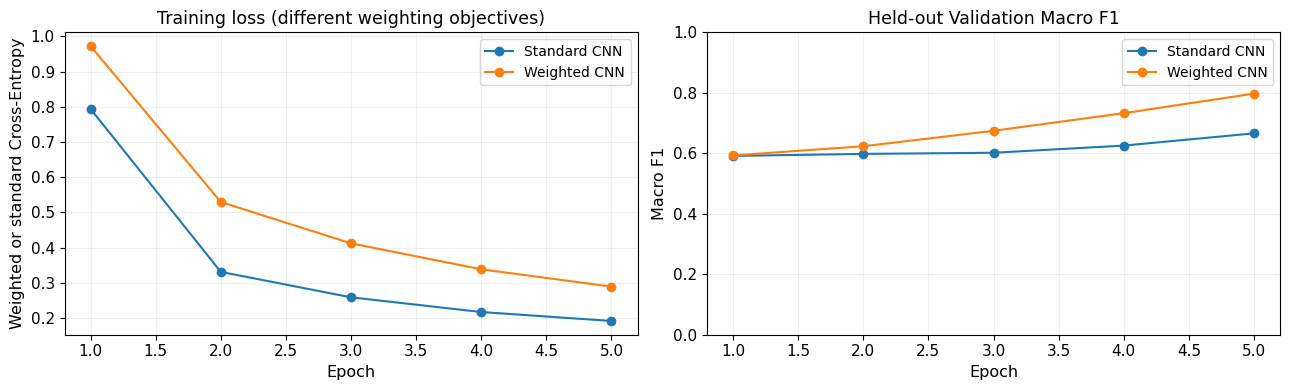

In [7]:
# =============== 06. Compare Loss-Ablation Validation Metrics ================

# ----------------------- 1. Compare Validation Metrics -----------------------
summary = pd.DataFrame([
    {"model": name,
     "macro_f1": f1_score(
         y_val, result["predicted"], labels=TASK_CLASSES,
         average="macro", zero_division=0),
     "balanced_accuracy": balanced_accuracy_score(y_val, result["predicted"]),
     "validation_windows": len(y_val)}
    for name, result in runs.items()
])

display(summary.round(4))

# ----------------- 2. Inspect Training and Validation Curves -----------------
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for name, result in runs.items():
    curve = result["history"]
    axes[0].plot(curve["epoch"], curve["train_loss"], marker="o", label=name)
    axes[1].plot(curve["epoch"], curve["validation_macro_f1"], marker="o", label=name)

axes[0].set(title="Training loss (different weighting objectives)",
            xlabel="Epoch", ylabel="Weighted or standard Cross-Entropy")
axes[1].set(title="Held-out Validation Macro F1", xlabel="Epoch",
            ylabel="Macro F1", ylim=(0, 1))
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.2)

fig.tight_layout()
save_figure(fig, output_dir / "05_loss_training_curves.png")
plt.show()


**07. Inspect Loss-Ablation Class Errors**

Inspect per-class precision, recall, F1 and support for both CNNs, with particular attention to minority activities and matched confusion matrices.


,model,class,support,precision,recall,f1
0,Standard CNN,Walking,453,0.8848,0.9492,0.9159
1,Standard CNN,Running,78,0.9873,1.0000,0.9936
2,Standard CNN,Shuffling,15,0.0000,0.0000,0.0000
3,Standard CNN,Stairs ascending,30,1.0000,0.1000,0.1818
4,Standard CNN,Stairs descending,32,1.0000,0.1875,0.3158
5,Standard CNN,Standing,536,0.9348,0.9366,0.9357
6,Standard CNN,Sitting,1363,0.9749,0.9993,0.9870
7,Standard CNN,Lying,194,1.0000,0.9948,0.9974
8,Weighted CNN,Walking,453,0.9663,0.8852,0.9240
9,Weighted CNN,Running,78,1.0000,0.9744,0.9870


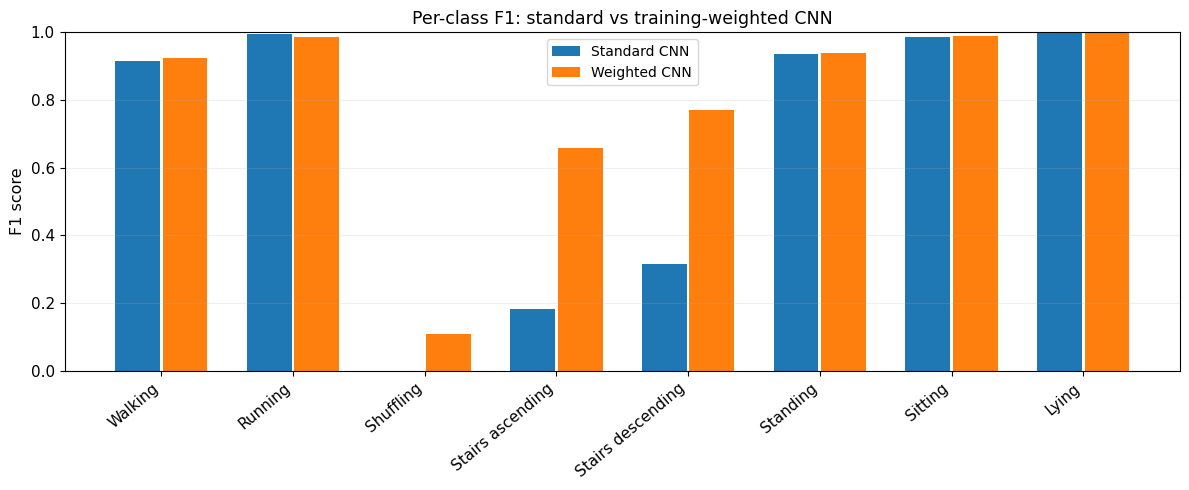

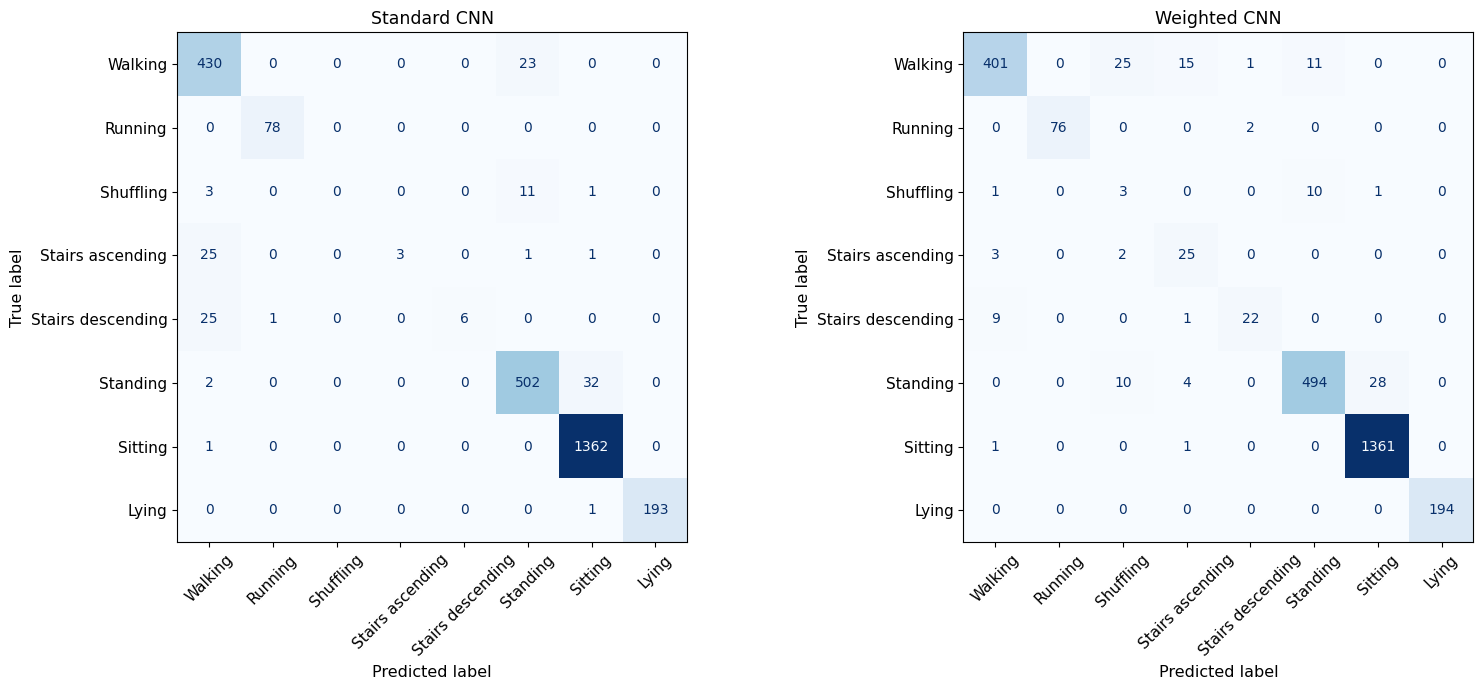

In [8]:
# ================== 07. Inspect Loss-Ablation Class Errors ===================

# --------------------- 1. Calculate Class-Level Metrics ----------------------
reports = []

for name, result in runs.items():
    report = classification_class_report(
        y_val, result["predicted"], classes=TASK_CLASSES,
        class_names=[ACTIVITY_NAMES[c] for c in TASK_CLASSES],
    )
    report["model"] = name
    reports.append(report)
class_table = pd.concat(reports, ignore_index=True)

display(class_table[["model", "class", "support", "precision", "recall", "f1"]].round(4))

# -------------------- 2. Compare Class F1 and Confusions ---------------------
fig, ax = plt.subplots(figsize=(12, 5))
positions = np.arange(len(TASK_CLASSES))

for i, name in enumerate(runs):
    values = class_table.loc[class_table["model"] == name, "f1"].to_numpy()
    ax.bar(positions + (i - 0.5) * 0.36, values, width=0.34, label=name)
ax.set_xticks(positions, [ACTIVITY_NAMES[c] for c in TASK_CLASSES], rotation=40, ha="right")
ax.set(title="Per-class F1: standard vs training-weighted CNN",
       ylabel="F1 score", ylim=(0, 1))
ax.grid(axis="y", alpha=0.2)
ax.legend()
fig.tight_layout()
save_figure(fig, output_dir / "05_loss_per_class_f1.png")
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, (name, result) in zip(axes, runs.items()):
    matrix = confusion_matrix(y_val, result["predicted"], labels=TASK_CLASSES)
    ConfusionMatrixDisplay(
        confusion_matrix=matrix, display_labels=[ACTIVITY_NAMES[c] for c in TASK_CLASSES],
    ).plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
    ax.set_title(name)
fig.tight_layout()
save_figure(fig, output_dir / "05_loss_confusion_matrices.png")
plt.show()


**08. Compare Paired Validation Participant Scores**

Measure fixed-task Macro F1 per Validation participant and describe weighted-minus-standard CNN differences without treating correlated windows as independent people.


,subject_id,score_a,score_b,difference_a_minus_b
0,S009,0.3304,0.2318,0.0986
1,S012,0.8951,0.5911,0.3040
2,S019,0.8374,0.5911,0.2462
3,S022,0.9012,0.6290,0.2722
4,S036,0.4838,0.5745,-0.0908
5,S037,0.7780,0.7463,0.0318


,model_a,model_b,metric,participants,mean_difference,median_difference,model_a_wins,model_b_wins,ties
0,Weighted CNN,Standard CNN,macro_f1_fixed_task,6,0.1437,0.1724,5,1,0


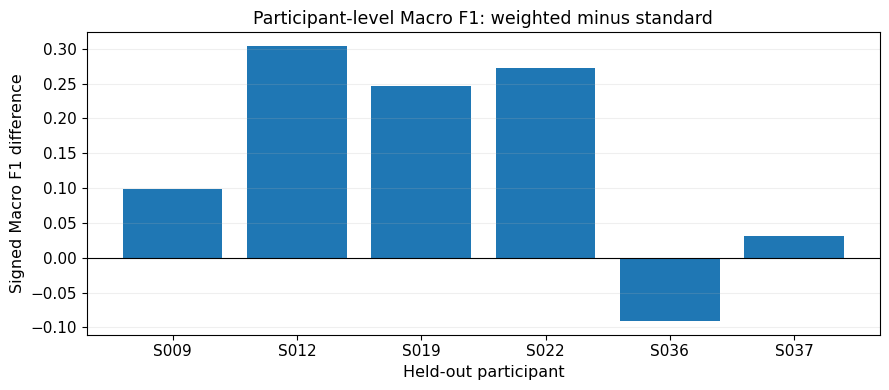

In [9]:
# ============= 08. Compare Paired Validation Participant Scores ==============

# ------------------- 1. Evaluate Paired Participant Scores -------------------
individual_results = pd.concat([
    evaluate_predictions_by_subject(
        y_val, result["predicted"], val_subject_ids,
        TASK_CLASSES, model_name=name,
    )
    for name, result in runs.items()
], ignore_index=True)
paired, paired_summary = compare_models_by_subject(
    individual_results, model_a="Weighted CNN", model_b="Standard CNN",
    score_column="macro_f1_fixed_task",
)

# ------------------- 2. Visualise Per-Participant Changes --------------------
display(paired.round(4))
display(pd.DataFrame([paired_summary]).round(4))
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(paired["subject_id"], paired["difference_a_minus_b"])
ax.axhline(0, color="black", linewidth=0.8)
ax.set(title="Participant-level Macro F1: weighted minus standard",
       xlabel="Held-out participant", ylabel="Signed Macro F1 difference")
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
save_figure(fig, output_dir / "05_loss_paired_subject_difference.png")
plt.show()


**09. Export Fixed-Split Loss-Ablation Results**

Save full-precision loss-ablation metrics, support tables, source-aligned predictions, paired participant scores, learning histories, model weights and figures in the `05_loss_` output family.


In [10]:
# =============== 09. Export Fixed-Split Loss-Ablation Results ================

# ---------------------- 1. Save Loss-Ablation Evidence -----------------------
overview.to_csv(output_dir / "05_bounded_development_cohort_summary.csv", index=False)
pd.DataFrame([
    {"partition": "unused_development" if name == "test" else name,
     "subject_id": subject}
    for name, indices in parts.items()
    for subject in sorted(set(metadata.iloc[indices]["subject_id"]))
]).to_csv(output_dir / "05_loss_partition_membership.csv", index=False)
weight_table.to_csv(output_dir / "05_loss_training_class_weights.csv", index=False)
summary.to_csv(output_dir / "05_loss_validation_metrics.csv", index=False)
class_table.to_csv(output_dir / "05_loss_per_class_metrics.csv", index=False)
individual_results.to_csv(output_dir / "05_loss_per_subject_metrics.csv", index=False)
paired.to_csv(output_dir / "05_loss_paired_subjects.csv", index=False)
pd.DataFrame([paired_summary]).to_csv(
    output_dir / "05_loss_paired_summary.csv", index=False
)
for name, run in runs.items():
    safe_name = "weighted" if name == "Weighted CNN" else "standard"
    run["history"].to_csv(
        output_dir / f"05_loss_{safe_name}_cnn_training_history.csv", index=False
    )
    pd.DataFrame(confusion_matrix(
        y_val, run["predicted"], labels=TASK_CLASSES
    ), index=TASK_CLASSES, columns=TASK_CLASSES).rename_axis(
        "true_source_code"
    ).to_csv(output_dir / f"05_loss_{safe_name}_validation_confusion.csv")
    torch.save({
        "model_state_dict": {k: v.detach().cpu() for k, v in run["model"].state_dict().items()},
        "architecture": {"name": "TemporalCNN", "in_channels": 6,
                         "n_classes": 8, "hidden_channels": 32},
        "task_classes": list(TASK_CLASSES),
        "train_only_channel_mean": run["scaler"]["channel_mean"].tolist(),
        "train_only_channel_std": run["scaler"]["channel_std"].tolist(),
        "class_weighting": "inverse_sqrt" if safe_name == "weighted" else "none",
    }, output_dir / f"05_loss_{safe_name}_cnn.pt")
pd.DataFrame({
    "source_row": np.tile(val_idx, len(runs)),
    "subject_id": np.tile(val_subject_ids, len(runs)),
    "true_source_code": np.tile(y_val, len(runs)),
    "model": np.repeat(list(runs.keys()), len(y_val)),
    "predicted_source_code": np.concatenate([r["predicted"] for r in runs.values()]),
}).to_csv(output_dir / "05_loss_validation_predictions.csv", index=False)
print("Saved Development Validation loss-ablation evidence in:", output_dir)


Saved Development Validation loss-ablation evidence in: /content/human-movement-intelligence/wearable_activity_recognition/output


**10. Run Three-Model Matched GroupKFold**

Evaluate Random Forest, standard CNN and weighted CNN in three whole-participant folds. Random Forest uses 30 deterministic features and 120 trees; CNNs use raw six-channel windows and Train-only scaling. Each training fold determines its own loss weights.


In [11]:
# ================== 10. Run Three-Model Matched GroupKFold ===================

# -------------------- 1. Set Grouped Comparison Protocol ---------------------
FOLDS = 3
EPOCHS = 5


# --------------------- 2. Run Matched GroupKFold Models ----------------------
fold_results, subject_results, class_results, prediction_records = compare_models_group_cv(
    windows=X,
    labels=y,
    subject_ids=metadata["subject_id"].to_numpy(),
    classes=TASK_CLASSES,
    channel_names=SENSOR_COLUMNS,
    n_splits=FOLDS,
    epochs=EPOCHS,
    batch_size=128,
    learning_rate=1e-3,
    random_state=42,
    device=DEVICE,
    forbidden_subject_ids=RESERVED_TEST,  # Exclude reserved Test participants from the evaluation.
)

# --------------------- 3. Inspect Held-Out Fold Results ----------------------
display(fold_results[[
    "fold", "model", "validation_subjects", "train_windows",
    "validation_windows", "validation_classes_present",
    "macro_f1", "balanced_accuracy"
]].round(4))


Input windows: (14201, 6, 100)
Feature matrix: (14201, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
Fold 1/3: fitting Standard CNN
Epoch 1/5 | loss=0.8096 | validation Macro F1=0.5744
Epoch 2/5 | loss=0.3466 | validation Macro F1=0.5848
Epoch 3/5 | loss=0.2615 | validation Macro F1=0.5869
Epoch 4/5 | loss=0.2130 | validation Macro F1=0.5899
Epoch 5/5 | loss=0.1872 | validation Macro F1=0.6311
Fold 1/3: fitting Weighted CNN
Epoch 1/5 | loss=1.0101 | validation Macro F1=0.5766
Epoch 2/5 | loss=0.5557 | validation Macro F1=0.6125
Epoch 3/5 | loss=0.4243 | validation Macro F1=0.7223
Epoch 4/5 | loss=0.3267 | validation Macro F1=0.7530
Epoch 5/5 | loss=0.2661 | validation Macro F1=0.7273
Fold 1: 19 Train subjects, 10 held-out subjects
Fold 2/3: fitting Standard CNN
Epoch 1/5 | loss=0.7609 | validation Macro F1=0.5946
Epoch 2/5 | loss=0.3078 | validation Macro F1=0.5956
Epoch 3/5 | loss=0.2400 | validation Macro F1=0.6011
Epoch 4/5 | loss=0.2016 | validation Macro F1=0.6121
E

,fold,model,validation_subjects,train_windows,validation_windows,validation_classes_present,macro_f1,balanced_accuracy
0,1,Random Forest,"S006, S012, S015, S018, S021, S025, S028, S031...",9201,5000,8,0.7969,0.8368
1,1,Standard CNN,"S006, S012, S015, S018, S021, S025, S028, S031...",9201,5000,8,0.6311,0.6261
2,1,Weighted CNN,"S006, S012, S015, S018, S021, S025, S028, S031...",9201,5000,8,0.7273,0.8198
3,2,Random Forest,"S009, S010, S014, S017, S020, S024, S027, S030...",9500,4701,8,0.7669,0.7608
4,2,Standard CNN,"S009, S010, S014, S017, S020, S024, S027, S030...",9500,4701,8,0.6654,0.6481
5,2,Weighted CNN,"S009, S010, S014, S017, S020, S024, S027, S030...",9500,4701,8,0.7951,0.7783
6,3,Random Forest,"S008, S013, S016, S019, S022, S026, S029, S033...",9701,4500,8,0.8645,0.8213
7,3,Standard CNN,"S008, S013, S016, S019, S022, S026, S029, S033...",9701,4500,8,0.5939,0.6068
8,3,Weighted CNN,"S008, S013, S016, S019, S022, S026, S029, S033...",9701,4500,8,0.8273,0.8176


**11. Compare Grouped Fold-Level Scores**

Report three-fold Macro F1 means and fold standard deviations and Balanced Accuracy. Fold-level statistics are descriptive because training folds share participants.


,model,macro_f1_mean,macro_f1_sd,balanced_accuracy_mean
0,Random Forest,0.8094,0.0500,0.8063
1,Standard CNN,0.6301,0.0357,0.6270
2,Weighted CNN,0.7832,0.0510,0.8052


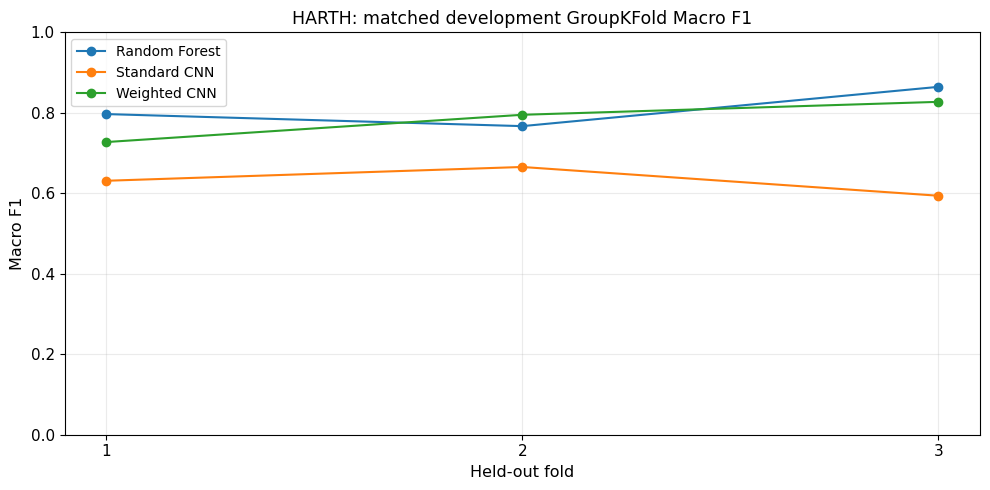

In [12]:
# =================== 11. Compare Grouped Fold-Level Scores ===================

# -------------------- 1. Summarise Fold-Level Performance --------------------
fold_summary = fold_results.groupby("model", as_index=False).agg(
    macro_f1_mean=("macro_f1", "mean"),
    macro_f1_sd=("macro_f1", "std"),
    balanced_accuracy_mean=("balanced_accuracy", "mean"),
)

display(fold_summary.round(4))

# ------------------------ 2. Visualise Fold Variation ------------------------
fig, ax = plt.subplots(figsize=(10, 5))

for name, table in fold_results.groupby("model", sort=False):
    table = table.sort_values("fold")
    ax.plot(table["fold"], table["macro_f1"], marker="o", label=name)

ax.set(title="HARTH: matched development GroupKFold Macro F1",
       xlabel="Held-out fold", ylabel="Macro F1", ylim=(0, 1),
       xticks=list(range(1, FOLDS + 1)))
ax.legend()
ax.grid(alpha=0.25)
fig.tight_layout()
save_figure(fig, output_dir / "05_cv_fold_macro_f1.png")
plt.show()


**12. Inspect Grouped Out-of-Fold Activity F1**

Compare class-level metrics on the matched out-of-fold Development windows; every source row contributes once per model.


,model,activity,support,precision,recall,f1
0,Random Forest,Walking,3591,0.9272,0.9510,0.9390
1,Random Forest,Running,1028,0.9836,0.9903,0.9869
2,Random Forest,Shuffling,219,0.4756,0.5342,0.5032
3,Random Forest,Stairs ascending,192,0.7310,0.5521,0.6291
4,Random Forest,Stairs descending,182,0.7031,0.4945,0.5806
5,Random Forest,Standing,2227,0.9382,0.9618,0.9499
6,Random Forest,Sitting,5599,0.9969,0.9791,0.9879
7,Random Forest,Lying,1163,0.9831,0.9991,0.9910
8,Standard CNN,Walking,3591,0.8880,0.9499,0.9179
9,Standard CNN,Running,1028,0.9835,0.9864,0.9849


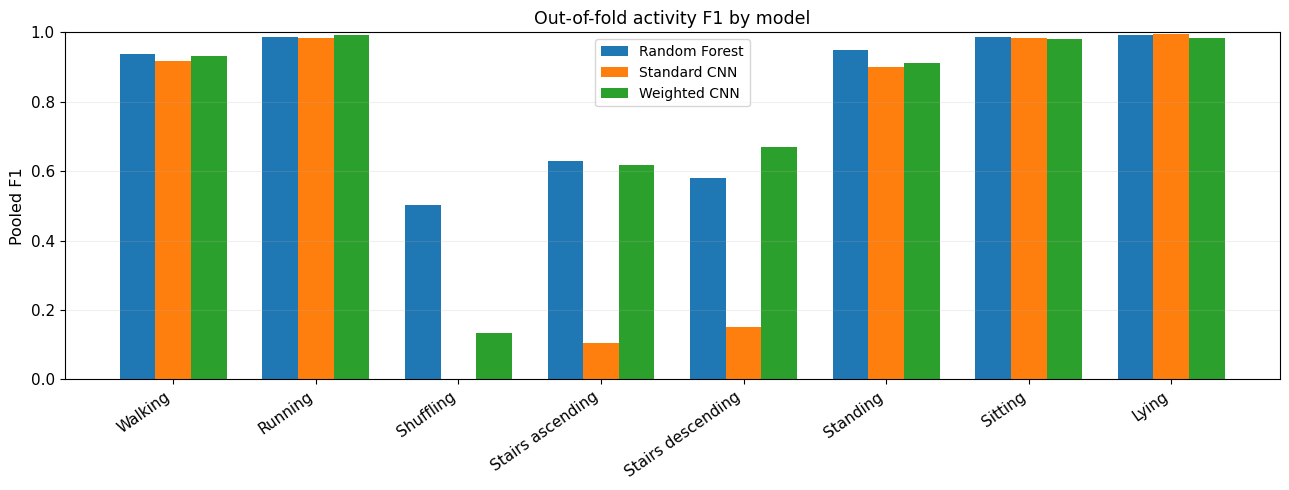

In [13]:
# ================ 12. Inspect Grouped Out-of-Fold Activity F1 ================

# --------------------- 1. Calculate Pooled Class Metrics ---------------------
class_results["activity"] = class_results["class"].map(
    lambda code: ACTIVITY_NAMES[int(code)]
)

display(class_results[[
    "model", "activity", "support", "precision", "recall", "f1"
]].round(4))
fig, ax = plt.subplots(figsize=(13, 5))

# ------------------------- 2. Compare Matched Models -------------------------
names = ["Random Forest", "Standard CNN", "Weighted CNN"]
positions = np.arange(len(TASK_CLASSES))
bar_width = 0.25

for i, name in enumerate(names):
    values = class_results.loc[class_results["model"] == name, "f1"].to_numpy()
    ax.bar(positions + (i-1)*bar_width, values, width=bar_width, label=name)
ax.set_xticks(positions, [ACTIVITY_NAMES[c] for c in TASK_CLASSES],
              rotation=35, ha="right")

ax.set(title="Out-of-fold activity F1 by model",
       ylabel="Pooled F1", ylim=(0, 1))
ax.grid(axis="y", alpha=0.2)
ax.legend()
fig.tight_layout()
save_figure(fig, output_dir / "05_cv_per_class_f1.png")
plt.show()


**13. Compare Paired Development Participant Effects**

Compare weighted CNN with standard CNN and Random Forest using the same 29 participants and fixed eight-class Macro F1. Preserve both signed differences.


,fold,model,subject_id,windows,observed_classes,macro_f1_fixed_task
0,1,Random Forest,S006,500,7,0.6826
10,1,Standard CNN,S006,500,7,0.4598
20,1,Weighted CNN,S006,500,7,0.6218
60,3,Random Forest,S008,500,5,0.4254
69,3,Standard CNN,S008,500,5,0.3339
...,...,...,...,...,...,...
49,2,Standard CNN,S037,500,7,0.6948
59,2,Weighted CNN,S037,500,7,0.8314
9,1,Random Forest,S038,500,8,0.8608
19,1,Standard CNN,S038,500,8,0.6175


,model_a,model_b,metric,participants,mean_difference,median_difference,model_a_wins,model_b_wins,ties
0,Weighted CNN,Standard CNN,macro_f1_fixed_task,29,0.1381,0.147,27,2,0


,model_a,model_b,metric,participants,mean_difference,median_difference,model_a_wins,model_b_wins,ties
0,Weighted CNN,Random Forest,macro_f1_fixed_task,29,-0.0082,-0.0112,14,15,0


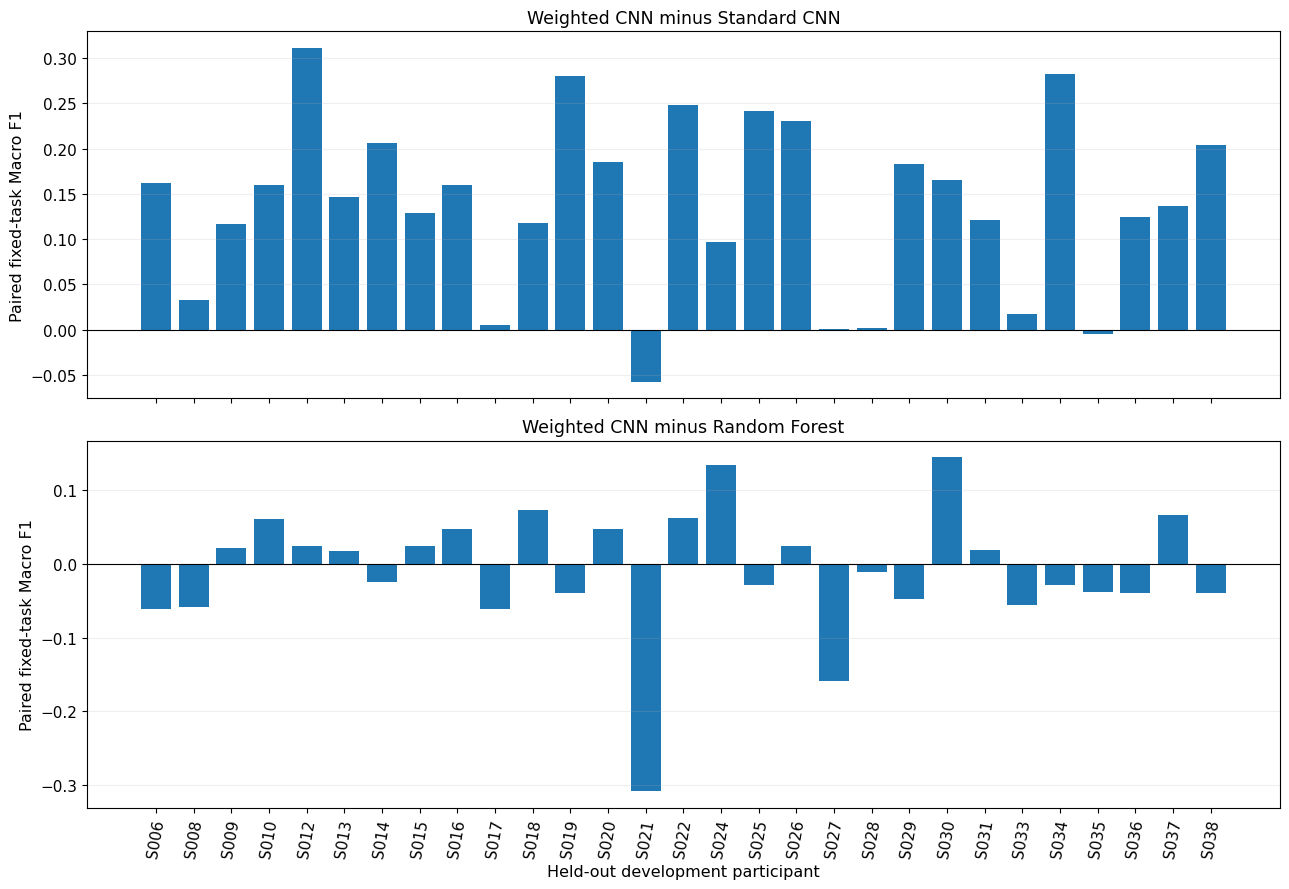

In [14]:
# ============ 13. Compare Paired Development Participant Effects =============

# ------------------- 1. Calculate Participant-Level Scores -------------------
display(subject_results[[
    "fold", "model", "subject_id", "windows",
    "observed_classes", "macro_f1_fixed_task"
]].sort_values(["subject_id", "model"]).round(4))
comparisons = [
    ("Weighted CNN", "Standard CNN"),
    ("Weighted CNN", "Random Forest"),
]

# ---------------------- 2. Compare Paired Participants -----------------------
fig, axes = plt.subplots(2, 1, figsize=(13, 9), sharex=True)

for ax, (model_a, model_b) in zip(axes, comparisons):
    paired, pair_summary = compare_models_by_subject(
        subject_results, model_a=model_a, model_b=model_b,
        score_column="macro_f1_fixed_task",
    )
    display(pd.DataFrame([pair_summary]).round(4))
    ax.bar(paired["subject_id"], paired["difference_a_minus_b"])
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set(title=f"{model_a} minus {model_b}",
           ylabel="Paired fixed-task Macro F1")
    ax.grid(axis="y", alpha=0.2)

axes[-1].tick_params(axis="x", rotation=80)
axes[-1].set_xlabel("Held-out development participant")
fig.tight_layout()
save_figure(fig, output_dir / "05_cv_paired_subject_f1.png")
plt.show()


**14. Export Matched GroupKFold Evidence**

Save three-model fold, class and participant metrics, paired comparisons and complete out-of-fold predictions under `05_cv_` names, then package the stage's current research outputs.


In [15]:
# ================== 14. Export Matched GroupKFold Evidence ===================

# ------------------------- 1. Protect OOF Alignment --------------------------
if set(subject_results["subject_id"]) != set(DEVELOPMENT_SUBJECTS):
    raise ValueError("Out-of-fold evaluation is missing Development participants.")
if set(subject_results["subject_id"]) & RESERVED_TEST:
    raise ValueError("Reserved participants appeared in Development evaluation.")
if len(fold_results) != 3 * FOLDS:
    raise ValueError("Some model/fold evaluations are missing.")
for model_name, frame in prediction_records.groupby("model"):
    ordered = frame.sort_values("source_row")
    if ordered["source_row"].tolist() != list(range(len(X))):
        raise ValueError(f"Missing or duplicated OOF source rows: {model_name}.")
    if not np.array_equal(ordered["true_label"].to_numpy(), y):
        raise ValueError(f"Out-of-fold source labels are misaligned: {model_name}.")

# ------------------------ 2. Save Grouped CV Evidence ------------------------
overview.to_csv(output_dir / "05_cv_development_cohort_summary.csv", index=False)
coverage.rename_axis("subject_id").reset_index().to_csv(
    output_dir / "05_cv_development_activity_coverage.csv", index=False
)
fold_results.to_csv(output_dir / "05_cv_fold_metrics.csv", index=False)
fold_summary.to_csv(output_dir / "05_cv_model_summary.csv", index=False)
subject_results.to_csv(output_dir / "05_cv_subject_metrics.csv", index=False)
class_results.to_csv(output_dir / "05_cv_per_class_metrics.csv", index=False)
prediction_records.to_csv(output_dir / "05_cv_oof_predictions.csv", index=False)

paired_rows, pair_summaries = [], []
for model_a, model_b in comparisons:
    pair_table, pair_stats = compare_models_by_subject(
        subject_results, model_a=model_a, model_b=model_b,
        score_column="macro_f1_fixed_task",
    )
    pair_table = pair_table.copy()
    pair_table["model_a"] = model_a
    pair_table["model_b"] = model_b
    paired_rows.append(pair_table)
    pair_summaries.append({"model_a": model_a, "model_b": model_b, **pair_stats})
pd.concat(paired_rows, ignore_index=True).to_csv(
    output_dir / "05_cv_paired_subjects.csv", index=False
)
pd.DataFrame(pair_summaries).to_csv(
    output_dir / "05_cv_paired_summary.csv", index=False
)
print("Saved Development-only matched model evidence in:", output_dir)

download_outputs_from_colab(folder="wearable_activity_recognition/output", stage="05")


Saved Development-only matched model evidence in: /content/human-movement-intelligence/wearable_activity_recognition/output
------------------------------------------------------------------------
Notebook stage: 05
Files packaged: 31
  + 05_bounded_development_cohort_summary.csv
  + 05_cv_development_activity_coverage.csv
  + 05_cv_development_cohort_summary.csv
  + 05_cv_fold_macro_f1.png
  + 05_cv_fold_metrics.csv
  + 05_cv_model_summary.csv
  + 05_cv_oof_predictions.csv
  + 05_cv_paired_subject_f1.png
  + 05_cv_paired_subjects.csv
  + 05_cv_paired_summary.csv
  + 05_cv_per_class_f1.png
  + 05_cv_per_class_metrics.csv
  + 05_cv_subject_metrics.csv
  + 05_loss_confusion_matrices.png
  + 05_loss_paired_subject_difference.png
  + 05_loss_paired_subjects.csv
  + 05_loss_paired_summary.csv
  + 05_loss_partition_membership.csv
  + 05_loss_per_class_f1.png
  + 05_loss_per_class_metrics.csv
  + 05_loss_per_subject_metrics.csv
  + 05_loss_standard_cnn.pt
  + 05_loss_standard_cnn_training_his

**15. Scientific Interpretation and Research Boundaries**

**Dataset and independent unit:** The bounded eight-class HARTH cohort contains temporally contiguous, label-pure two-second windows. A 500-window per-person cap changes the activity distribution; overlapping windows cannot be treated as independent participants.

**Loss-ablation question:** The two CNNs differ only in Train-derived cross-entropy weighting on the same Train/Validation groups. Class-specific and participant-paired results complement aggregate Macro F1.

**Grouped-comparison question:** Three participant-disjoint folds compare configured Random Forest, standard CNN and weighted CNN pipelines on matched held-out windows. Different CNN raw-signal and Random Forest statistical representations prevent attribution of observed differences solely to architecture.

**Scope:** Fixed Validation and grouped Development evaluations use different protocols and are not pooled. Neither establishes independent external generalisation, real-time performance or statistical superiority; S023 and S032 are not assessed here.
